# 03 Delivery stages: pickup vs road (S6) and the leakage audit (S5)

**Owner:** Sumaiya · **Due:** Wed 11 Nov · **Covers:** proposal ("stage analysis will compare restaurant wait and
road time to identify where errors increase"; "leakage audit will compare the honest model with one using
post order timestamps"), research question part 2

Every delivery splits at the moment the courier picks the food up:
- **pickup stage** = order → pickup (`fetch_min`): dispatch, the courier accepting and getting to the restaurant,
  and waiting for the food. There's no "courier arrived at the restaurant" time, so the ride there and the food
  wait can't be fully separated.
- **road stage** = pickup → arrival (`delivery_min − fetch_min`).

Both are after-order times: analysis only, never model inputs (C7). **Training days only** (17–22 Oct); the test
days stay untouched. Saved figures go to `figures/eda/` (PDF + 300-dpi PNG): the leakage chart (§7) for the report, stages by area (§6)
for a backup slide. The §4 and §5 figures stay in the notebook.

In [1]:
import json, sys; sys.path.insert(0, "..")   # so `common` imports work from notebooks/
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from common import split
from common.config import RESULTS
from common.data import load_table
from common.features import FEATURE_SETS
from experiments.run import cross_validate

pd.set_option("display.max_columns", 30)   # show all 24 hours in the hour table
FIG_DIR = Path("../figures/eda"); FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # same palette as 01/02; orange = platform only
INK, MUTED, GREY, LIGHT, GRID = "#1f1f1f", "#6b6b6b", "#9a9a9a", "#d9d9d9", "#e6e6e6"
COL1, COL2 = 3.5, 7.16                  # IEEE one column / full page width (inches)
plt.rcParams.update({"font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titlesize": 9, "pdf.fonttype": 42,
                     "font.family": "DejaVu Sans"})
PICKUP, ROAD = BLUE, AQUA


def save(fig, name):
    """PDF for the report, 300-dpi PNG for the slides."""
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")


def grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=0.6); ax.set_axisbelow(True)


t, _ = split.train_test(load_table())
t = t.copy()
t["pickup"] = t["fetch_min"]
t["road"] = t["delivery_min"] - t["fetch_min"]
# Distance is known at order time and the model already uses it, so "after distance" = minus the median
# for the order's 0.25-km band. Left over is what distance doesn't explain.
km_band = pd.cut(t["dist_haversine_km"].clip(upper=8), np.arange(0, 8.25, 0.25), include_lowest=True)
for col in ["pickup", "road", "delivery_min"]:
    t[f"{col}_adj"] = t[col] - t.groupby(km_band, observed=True)[col].transform("median")
t["late"] = t["delivery_min"] > t["promise_min"]
print(f"{len(t):,} orders on the training days")

406,553 orders on the training days


## 1. The split, and what's inside the pickup stage

In [2]:
assert np.allclose(t["pickup"] + t["road"], t["delivery_min"])
parts = pd.DataFrame({"order to dispatch": t["dispatch_min"],
                      "dispatch to courier accepts": t["grab_min"] - t["dispatch_min"],
                      "accepts to pickup (ride there + food wait)": t["fetch_min"] - t["grab_min"],
                      "pickup stage, total": t["pickup"], "road stage": t["road"], "delivery time": t["delivery_min"]})
print("negative durations:", int((parts < 0).sum().sum()), "| missing:", int(parts.isna().sum().sum()))
past_ready = (t["fetch_min"] - t["prep_min"])[t["prep_min"].notna()]
print(f"picked up after the estimated ready time: {(past_ready > 0).mean():.0%} of orders with an estimate "
      f"(median {past_ready[past_ready > 0].median():.1f} min after it)")
print(f"Spearman with distance: pickup {spearmanr(t['pickup'], t['dist_haversine_km']).correlation:.2f}, "
      f"road {spearmanr(t['road'], t['dist_haversine_km']).correlation:.2f}")
parts.describe(percentiles=[.25, .5, .75, .9]).T[["25%", "50%", "75%", "90%", "mean"]].round(1)

negative durations: 0 | missing: 0
picked up after the estimated ready time: 45% of orders with an estimate (median 4.1 min after it)


Spearman with distance: pickup 0.04, road 0.70


,25%,50%,75%,90%,mean
order to dispatch,0.7,2.7,6.1,9.2,4.0
dispatch to courier accepts,0.1,0.2,0.3,0.7,0.4
accepts to pickup (ride there + food wait),5.6,8.9,13.1,17.8,10.0
"pickup stage, total",9.3,13.1,18.0,23.7,14.4
road stage,8.0,13.1,20.2,27.8,15.0
delivery time,20.8,27.8,36.4,45.6,29.5


**Reading:** the two stages take the same median time, 13.1 min each. Inside the pickup stage, dispatch is quick
(median 2.7 min) and couriers accept almost at once (0.2 min). Most of it is between accepting and pickup (8.9
min): the ride to the restaurant plus the wait for the food. 45% of orders with an estimate are picked up after
the estimated ready time, a median 4.1 min after it, so either the food or the courier runs late in nearly half
of them; the data can't say which. Pickup doesn't depend on the customer's distance (Spearman 0.04), the road
does (0.70).

## 2. Which stage varies more?
Raw, the road varies more, but most of that is distance. After distance is taken out, the comparison is fair.

In [3]:
var = pd.DataFrame({"raw": [t["pickup"].var(), t["road"].var(), t[["pickup", "road"]].cov().iloc[0, 1], t["delivery_min"].var()],
                    "after distance": [t["pickup_adj"].var(), t["road_adj"].var(), t[["pickup_adj", "road_adj"]].cov().iloc[0, 1],
                                       t["delivery_min_adj"].var()]},
                   index=["pickup variance", "road variance", "covariance", "delivery variance"])
for c in var:
    var.loc["pickup share (%)", c] = 100 * var.loc["pickup variance", c] / (var.loc["pickup variance", c] + var.loc["road variance", c])
var.round(1)

,raw,after distance
pickup variance,55.0,54.8
road variance,84.7,47.8
covariance,0.8,-1.6
delivery variance,141.3,99.4
pickup share (%),39.4,53.4


**Reading:** raw, the road varies more (variance 85 vs 55). That's mostly distance, which the model already knows.
After distance it flips: pickup 54.8 vs road 47.8, so pickup is 53% of what distance doesn't explain. The two
stages hardly move together (covariance about 0): a slow pickup doesn't mean a slow ride.

## 3. Late orders: where do they lose the time?
Late = arrived after the promise. Minutes beyond the usual for the same distance, by stage.

In [4]:
slow = t["delivery_min_adj"] > t["delivery_min_adj"].quantile(0.8)
lost = pd.DataFrame({
    "late": t.loc[t["late"], ["pickup_adj", "road_adj"]].mean(),
    "on time": t.loc[~t["late"], ["pickup_adj", "road_adj"]].mean(),
    "slowest 20% (after distance)": t.loc[slow, ["pickup_adj", "road_adj"]].mean(),
    "other 80%": t.loc[~slow, ["pickup_adj", "road_adj"]].mean()}).T
lost.columns = ["pickup (min vs usual)", "road (min vs usual)"]
print(f"late: {t['late'].mean():.1%} of orders")
lost.round(1)

late: 14.7% of orders


,pickup (min vs usual),road (min vs usual)
late,7.4,8.2
on time,0.3,0.3
slowest 20% (after distance),9.2,8.6
other 80%,-0.7,-0.4


**Reading:** late orders (14.7%) lose time in both stages, about equally: 7.4 min more than usual at pickup and
8.2 on the road, against 0.3 for orders on time. The slowest fifth looks the same (9.2 and 8.6).

## 4. Where do the model's errors increase? [notebook]
The frozen HGB (`experiments/final_params/hgb.json`, same as `experiments.final`) on the 4 CV folds. It reads the
saved predictions in `results/final/cv/hgb/` if they're there; otherwise it refits (about 2 min). For each stage:
the model's MAE by tenth of that stage's time after distance.

275,962 CV orders, HGB MAE 6.25
split of the model's (signed) error variance: pickup 51%, road 47%, rest 2%
by construction check: the error correlates 0.81 with the two stages added up


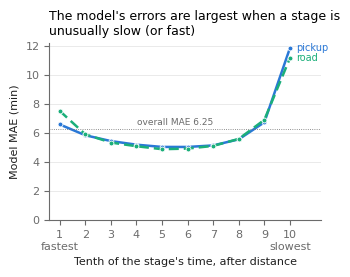

,0,1,2,3,4,5,6,7,8,9
pickup,6.60,5.85,5.45,5.20,5.04,5.04,5.15,5.57,6.74,11.86
road,7.53,5.92,5.35,5.09,4.89,4.93,5.11,5.60,6.91,11.17


In [5]:
saved = RESULTS / "final" / "cv" / "hgb" / "predictions.parquet"
if saved.exists():
    pred = pd.read_parquet(saved)
else:
    params = json.loads((Path("..") / "experiments" / "final_params" / "hgb.json").read_text())["params"]
    pred = cross_validate("hgb", FEATURE_SETS["base"], t, params)
m = t.set_index("order_id")[["pickup_adj", "road_adj", "hour", "district"]].join(
    pred.set_index("order_id")[["y", "pred"]], how="inner")
m["err"] = m["y"] - m["pred"]
m["abs_err"] = m["err"].abs()
print(f"{len(m):,} CV orders, HGB MAE {m['abs_err'].mean():.2f}")


# Additive split of the error variance: Var(e) = Cov(e, pickup_adj) + Cov(e, road_adj) + the rest. Partly by
# construction: pickup_adj + road_adj is close to the target after distance, and e = target - prediction.
share = {s: m["err"].cov(m[f"{s}_adj"]) / m["err"].var() for s in ["pickup", "road"]}
share["rest"] = 1 - sum(share.values())
print("split of the model's (signed) error variance: " + ", ".join(f"{k} {v:.0%}" for k, v in share.items()))
total_adj = m["pickup_adj"] + m["road_adj"]
print(f"by construction check: the error correlates {m['err'].corr(total_adj):.2f} with the two stages added up")

deciles = {s: m.groupby(pd.qcut(m[f"{s}_adj"], 10, labels=False))["abs_err"].mean() for s in ["pickup", "road"]}
fig, ax = plt.subplots(figsize=(COL1, 2.3))
x = np.arange(1, 11)
for s, col, ls in [("pickup", PICKUP, "-"), ("road", ROAD, (0, (4, 2)))]:
    ax.plot(x, deciles[s].values, color=col, lw=1.8, ls=ls, marker="o", ms=3.5, mec="white", mew=0.6)
    ax.text(10.25, deciles[s].iloc[-1], s, color=col, fontsize=7, va="center")
ax.axhline(m["abs_err"].mean(), color=MUTED, lw=0.6, ls=":")
ax.text(5.5, m["abs_err"].mean() + 0.3, f"overall MAE {m['abs_err'].mean():.2f}", ha="center", fontsize=6.5, color=MUTED)
ax.set_xticks(x, ["1\nfastest"] + [str(i) for i in range(2, 10)] + ["10\nslowest"])
ax.set_xlim(0.6, 11.2); ax.set_ylim(0, None)
ax.set_xlabel("Tenth of the stage's time, after distance"); ax.set_ylabel("Model MAE (min)")
grid(ax)
ax.set_title("The model's errors are largest when a stage is\nunusually slow (or fast)")
plt.show()
pd.DataFrame(deciles).round(2).T

**Reading:** the model is accurate when both stages are typical (MAE about 5 in the middle tenths) and worst when
a stage is unusually slow: 11.9 min in the slowest tenth of pickup, 11.2 for the road. The fastest tenths are
above average too (6.6 and 7.5). Splitting the model's error variance between the stages gives pickup 51% and
road 47% (2% left), so neither stage dominates.

This is partly by construction. The two stages add up to the delivery time, so after distance they are most of
what the model has to predict, and the error correlates 0.81 with their sum. The point isn't that the stages
explain the error; it's that the unpredictable part is split about evenly between them. That fits S5 (§7):
knowing the pickup time cuts MAE the most because it's the only after-order time that covers a whole stage. The
road stays unknown until arrival and carries about as much of the error.

## 5. By hour [notebook]

meal peaks vs other hours, after distance: pickup +2.7 min, road +2.7 min
late orders, meal peaks: +8.5 min at pickup, +9.6 on the road (vs usual for the distance)
late orders, other hours: +5.9 min at pickup, +6.3 on the road (vs usual for the distance)
model MAE by hour: highest 11:00 (7.04), then 18:00 (6.92); lowest 13:00 (5.22)


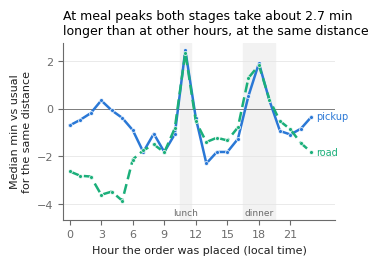

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
orders,3553.0,2293.0,1477.0,941.0,649.0,641.0,2170.0,4393.0,7234.0,8294.0,23170.0,69949.0,41913.0,20855.0,14815.0,13442.0,16275.0,37585.0,48965.0,34074.0,22302.0,15094.0,9900.0,6569.0
pickup,12.4,12.7,13.0,13.5,13.2,12.8,12.2,11.3,12.0,11.3,12.1,15.6,12.7,10.8,11.3,11.3,11.8,13.7,15.0,13.5,12.2,12.0,12.3,12.8
road,11.1,10.7,10.9,10.3,9.8,10.0,10.6,10.6,11.0,10.8,12.8,15.8,12.1,11.2,11.4,11.4,12.4,14.8,14.9,13.4,12.5,12.2,11.7,11.7
pickup_adj,-0.7,-0.5,-0.2,0.3,-0.1,-0.4,-0.9,-1.8,-1.1,-1.8,-1.1,2.5,-0.4,-2.3,-1.8,-1.8,-1.3,0.5,1.9,0.3,-0.9,-1.1,-0.8,-0.3
road_adj,-2.6,-2.8,-2.8,-3.6,-3.5,-3.9,-2.1,-1.7,-1.5,-1.8,-0.8,2.4,-0.5,-1.4,-1.2,-1.3,-0.8,1.3,1.8,0.4,-0.5,-0.9,-1.4,-1.8
late_pickup,7.8,7.7,9.9,11.1,11.2,12.7,8.4,6.6,7.1,7.4,6.7,9.7,6.4,3.9,5.2,5.4,6.3,7.3,8.8,6.5,4.8,4.6,5.1,6.6
late_road,4.9,3.5,3.1,3.3,2.8,1.9,3.9,3.7,4.2,5.0,7.8,10.1,6.7,6.1,6.4,6.2,7.6,9.7,9.9,8.1,6.7,6.4,5.2,4.3
model_mae,6.3,6.2,6.7,6.1,5.6,5.9,6.0,5.4,5.5,5.8,6.2,7.0,5.7,5.2,5.6,5.8,6.2,6.7,6.9,6.2,5.7,5.7,5.6,5.8


In [6]:
hourly = t.groupby("hour").agg(orders=("order_id", "size"), pickup=("pickup", "median"), road=("road", "median"),
                               pickup_adj=("pickup_adj", "median"), road_adj=("road_adj", "median"))
peak = t["lunch_peak"].eq(1) | t["dinner_peak"].eq(1)
rise = {s: t.loc[peak, f"{s}_adj"].median() - t.loc[~peak, f"{s}_adj"].median() for s in ["pickup", "road"]}
print("meal peaks vs other hours, after distance: " + ", ".join(f"{s} {v:+.1f} min" for s, v in rise.items()))
late = t[t["late"]]                                  # where late orders lose their time, by stage
late_peak = late["lunch_peak"].eq(1) | late["dinner_peak"].eq(1)
for name, rows in [("meal peaks", late_peak), ("other hours", ~late_peak)]:
    print(f"late orders, {name}: {late.loc[rows, 'pickup_adj'].mean():+.1f} min at pickup, "
          f"{late.loc[rows, 'road_adj'].mean():+.1f} on the road (vs usual for the distance)")
hourly["late_pickup"] = late.groupby("hour")["pickup_adj"].mean()
hourly["late_road"] = late.groupby("hour")["road_adj"].mean()
mae_hour = m.groupby("hour")["abs_err"].mean()
print(f"model MAE by hour: highest {mae_hour.idxmax()}:00 ({mae_hour.max():.2f}), then "
      f"{mae_hour.drop(mae_hour.idxmax()).idxmax()}:00 ({mae_hour.drop(mae_hour.idxmax()).max():.2f}); "
      f"lowest {mae_hour.idxmin()}:00 ({mae_hour.min():.2f})")

fig, ax = plt.subplots(figsize=(COL1, 2.3))
for h0, h1 in [(11, 11), (17, 19)]:
    ax.axvspan(h0 - 0.5, h1 + 0.5, color="#f2f2f2", zorder=0)
ax.axhline(0, color=MUTED, lw=0.6)
for s, col, ls in [("pickup", PICKUP, "-"), ("road", ROAD, (0, (4, 2)))]:
    ax.plot(hourly.index, hourly[f"{s}_adj"], color=col, lw=1.8, ls=ls, marker="o", ms=2.8, mec="white", mew=0.5)
    ax.text(23.4, hourly[f"{s}_adj"].iloc[-1], s, color=col, fontsize=7, va="center")
low = min(hourly["pickup_adj"].min(), hourly["road_adj"].min()) - 0.8
ax.text(11, low + 0.2, "lunch", ha="center", fontsize=6.5, color=MUTED)
ax.text(18, low + 0.2, "dinner", ha="center", fontsize=6.5, color=MUTED)
ax.set_xticks(range(0, 24, 3)); ax.set_xlim(-0.6, 25.2); ax.set_ylim(low, None)
ax.set_xlabel("Hour the order was placed (local time)"); ax.set_ylabel("Median min vs usual\nfor the same distance")
grid(ax)
if abs(rise["pickup"] - rise["road"]) < 0.3:
    title = f"At meal peaks both stages take about {np.mean(list(rise.values())):.1f} min\nlonger than at other hours, at the same distance"
else:
    title = f"At meal peaks pickup slows by {rise['pickup']:.1f} min and the road\nby {rise['road']:.1f} min, at the same distance"
ax.set_title(title)
plt.show()
hourly.assign(model_mae=mae_hour).round(1).T

**Reading:** both stages peak at the same hours. Raw medians: at 11:00 pickup is 15.6 min and the road 15.8; at
18:00, 15.0 and 14.9. At the same distance (the lines), both take about 2.7 min longer at meal peaks than at
other hours. At night pickup runs close to usual while the road is 2.6–3.9 min faster than usual.

Late orders (the table's `late_` rows): at meal peaks they lose a bit more on the road (+9.6 min) than at pickup
(+8.5); at other hours the two are close (+6.3, +5.9). At night it's the other way round: late orders lose their
time at pickup (at 05:00, +12.7 min vs +1.9 on the road). The
model's MAE follows the peaks: highest at 11:00 (7.04), then 18:00 (6.92), lowest at 13:00 (5.22).

## 6. By area [backup slide]
After distance, so an area isn't "slow" just for having longer trips. Areas sorted by the model's MAE, as in `errors_by_area`.

late orders lose more on the road in 7 of 23 areas (0, 1, 2, 5, 9, 12, 13), which hold 72% of late orders; median trip there 1.73 km vs 1.09 km elsewhere
spread across areas, after distance: pickup 5.0 min, road 4.3 min
Spearman, area pickup vs road (after distance): 0.28


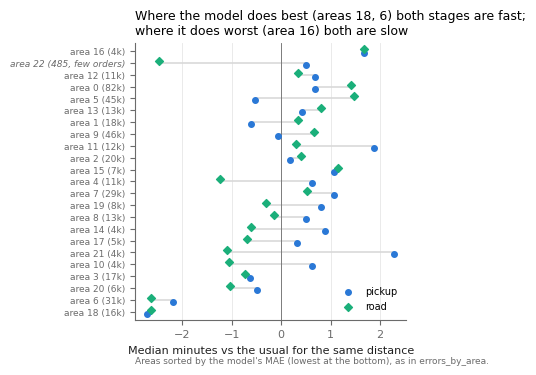

,orders,median_km,pickup,road,model_mae,late_orders,late_pickup,late_road
district,,,,,,,,
18,15537,1.04,-2.70,-2.63,4.15,483,5.68,2.42
6,30510,1.10,-2.18,-2.63,4.56,1419,7.31,2.15
20,5590,1.10,-0.48,-1.03,4.92,437,8.81,4.05
3,16583,1.07,-0.63,-0.73,5.21,1369,8.34,5.45
10,4172,1.02,0.63,-1.05,5.42,396,9.97,4.57
21,3801,0.92,2.28,-1.08,5.67,403,11.94,3.38
17,4919,1.08,0.32,-0.68,5.74,608,8.98,5.35
14,4361,1.13,0.88,-0.62,5.87,576,9.19,5.51
8,13316,1.07,0.50,-0.15,5.94,1431,8.79,6.25


In [7]:
area = t.groupby("district").agg(orders=("order_id", "size"), median_km=("dist_haversine_km", "median"),
                                 pickup=("pickup_adj", "median"), road=("road_adj", "median"))
area["model_mae"] = m.groupby("district")["abs_err"].mean()
area["late_orders"] = late.groupby("district").size()
area["late_pickup"] = late.groupby("district")["pickup_adj"].mean()
area["late_road"] = late.groupby("district")["road_adj"].mean()
road_led = area["late_road"] > area["late_pickup"]
print(f"late orders lose more on the road in {road_led.sum()} of {len(area)} areas ({', '.join(map(str, area.index[road_led]))}), "
      f"which hold {area.loc[road_led, 'late_orders'].sum() / area['late_orders'].sum():.0%} of late orders; "
      f"median trip there {area.loc[road_led, 'median_km'].median():.2f} km vs {area.loc[~road_led, 'median_km'].median():.2f} km elsewhere")
area = area.sort_values("model_mae")       # same order as errors_by_area (05_errors): lowest MAE at the bottom
spread = {s: area[s].max() - area[s].min() for s in ["pickup", "road"]}
print("spread across areas, after distance: " + ", ".join(f"{s} {v:.1f} min" for s, v in spread.items()))
print(f"Spearman, area pickup vs road (after distance): {spearmanr(area['pickup'], area['road']).correlation:.2f}")

fig, ax = plt.subplots(figsize=(COL1, 3.6))
y = np.arange(len(area))
ax.hlines(y, area[["pickup", "road"]].min(axis=1), area[["pickup", "road"]].max(axis=1), color=LIGHT, lw=1.2, zorder=1)
ax.scatter(area["pickup"], y - 0.17, color=PICKUP, s=16, zorder=3, label="pickup")   # small offsets so equal values stay visible
ax.scatter(area["road"], y + 0.17, color=ROAD, s=16, marker="D", zorder=3, label="road")
ax.axvline(0, color=MUTED, lw=0.6)
ax.set_yticks(y, [f"area {a} ({n / 1000:.0f}k)" if n >= 1000 else f"area {a} ({n}, few orders)" for a, n in area["orders"].items()],
              fontsize=6.5)
for lab, n in zip(ax.get_yticklabels(), area["orders"]):
    if n < 1000:
        lab.set_color(MUTED); lab.set_style("italic")
ax.set_xlabel("Median minutes vs the usual for the same distance")
ax.set_ylim(-0.7, len(area) - 0.3)
grid(ax, "x"); ax.legend(frameon=False, fontsize=7, loc="lower right")
big = area[area["orders"] >= 1000]
best, worst = list(big.index[:2]), big.index[-1]
ax.set_title(f"Where the model does best (areas {best[0]}, {best[1]}) both stages are fast;\n"
             f"where it does worst (area {worst}) both are slow")
ax.text(0.0, -0.13, "Areas sorted by the model's MAE (lowest at the bottom), as in errors_by_area.", transform=ax.transAxes,
        fontsize=6.5, color=MUTED, va="top")
save(fig, "stages_by_area")
plt.show()
area.round(2)

**Reading:** areas differ a bit more at pickup (5.0 min between the fastest and slowest) than on the road (4.3),
and the two barely line up (Spearman 0.28). Areas 18 and 6 are fast at both stages (about 2.5 min under the usual)
and have the lowest MAE (4.2 and 4.6). Area 16 is the opposite: slow at both (+1.7 each) and the highest MAE
(7.5). It isn't a clean rule, though: areas 10 and 17 have a slower-than-usual pickup but low MAE (5.4 and 5.7).
MAE here is raw, not adjusted for distance, and areas with longer trips (0, 5, 12) have higher MAE partly for that
reason. Area 22 has only 485 orders, so its values are noisy.

Where late orders lose their time: on the road in 7 areas (0, 1, 2, 5, 9, 12, 13), at pickup in the other 16.
The 7 road areas are the big ones with longer trips (median 1.73 km vs 1.09) and hold 72% of late orders.

## 7. Leakage audit (S5) [report]
The proposal: compare the honest model with one that also sees after-order times. Same frozen settings as
`experiments.final` (`experiments/final_params/`), same CV folds. `leaky` adds dispatch, courier-accepts (grab)
and pickup (fetch) times, all measured from the order; then HGB gets one of them at a time. Those one-at-a-time
sets are defined here, not in the frozen `common/features.py`, and are never model inputs (C7). About 10 min.

In [8]:
from common.evaluate import paired_bootstrap, point_metrics
from common.features import FeatureSet

base = FEATURE_SETS["base"]
one_at_a_time = {f"base + {c}": FeatureSet(c, (*base.numeric, c), base.categorical)
                 for c in ["dispatch_min", "grab_min", "fetch_min"]}
audit = []
for model in ["hgb", "elasticnet"]:
    params = json.loads((Path("..") / "experiments" / "final_params" / f"{model}.json").read_text())["params"]
    runs = {"base": pred if model == "hgb" else cross_validate(model, base, t, params),   # HGB base = §4's predictions
            "leaky": cross_validate(model, FEATURE_SETS["leaky"], t, params)}
    if model == "hgb":
        runs.update({name: cross_validate(model, fs, t, params) for name, fs in one_at_a_time.items()})
    for name, r in runs.items():
        metrics = point_metrics(r["y"], r["pred"])
        audit.append({"model": model, "features": name, "MAE": metrics["mae"], "R2": metrics["r2"]})
    boot = paired_bootstrap((runs["leaky"]["y"] - runs["leaky"]["pred"]).abs(), (runs["base"]["y"] - runs["base"]["pred"]).abs())
    print(f"{model}: leaky minus base {boot['diff']:+.2f} min (95% CI {boot['ci95'][0]:+.2f} to {boot['ci95'][1]:+.2f}), "
          f"{100 * boot['diff'] / boot['mae_b']:+.1f}%")
in_order = (t["dispatch_min"] <= t["grab_min"]) & (t["grab_min"] <= t["fetch_min"])
print(f"dispatch <= grab <= pickup for {in_order.mean():.1%} of orders: pickup time already contains the other two")
pd.DataFrame(audit).set_index(["model", "features"]).round(3)

hgb: leaky minus base -1.72 min (95% CI -1.74 to -1.71), -27.6%


elasticnet: leaky minus base -1.76 min (95% CI -1.78 to -1.74), -26.7%
dispatch <= grab <= pickup for 100.0% of orders: pickup time already contains the other two


MAE     R2
model      features                         
hgb        base                 6.250  0.506
           leaky                4.528  0.721
           base + dispatch_min  5.856  0.586
           base + grab_min      5.825  0.591
           base + fetch_min     4.548  0.718
elasticnet base                 6.597  0.467
           leaky                4.836  0.708

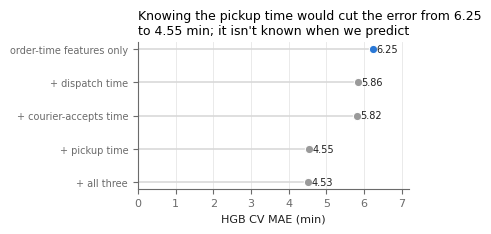

In [9]:
# Report figure: the five HGB runs as dots, in timeline order
hgb = pd.DataFrame(audit).query("model == 'hgb'").set_index("features")["MAE"]
rows = [("order-time features only", "base"), ("+ dispatch time", "base + dispatch_min"),
        ("+ courier-accepts time", "base + grab_min"), ("+ pickup time", "base + fetch_min"), ("+ all three", "leaky")]
fig, ax = plt.subplots(figsize=(COL1, 1.9))
y = np.arange(len(rows))[::-1]
for yi, (label, key) in zip(y, rows):
    ax.hlines(yi, 0, hgb[key], color=LIGHT, lw=1.2, zorder=1)
    ax.plot(hgb[key], yi, "o", color=BLUE if key == "base" else GREY, ms=6, mec="white", mew=0.8, zorder=3)
    ax.text(hgb[key] + 0.08, yi, f"{hgb[key]:.2f}", va="center", fontsize=7, color=INK)
ax.set_yticks(y, [r[0] for r in rows], fontsize=7)
ax.set_xlim(0, 7.2); ax.set_xlabel("HGB CV MAE (min)")
grid(ax, "x")
ax.set_title(f"Knowing the pickup time would cut the error from {hgb['base']:.2f}\nto {hgb['base + fetch_min']:.2f} min; "
             "it isn't known when we predict")
save(fig, "leakage_audit")
plt.show()

**Reading:** with after-order times the frozen models gain 27–28%: HGB 6.25 → 4.53 min (−1.72, 95% CI −1.74
to −1.71; R² 0.51 → 0.72), Elastic-Net 6.60 → 4.84 (−1.76, CI −1.78 to −1.74). One time at a time (HGB):
dispatch 5.86, courier accepts 5.82, pickup 4.55, so pickup alone gives almost all of the gain. That's partly by
construction: all three are measured from the order and dispatch ≤ accept ≤ pickup for every order, so the
pickup time contains the other two. It covers dispatch, the courier getting to the restaurant and waiting for
the food (§1). The 4.5 min left is the road stage (§4) and noise. None of these times is known when the order is
placed, so they're never model inputs (C7).

## 8. Conclusion
Pickup (order → pickup) and road (pickup → arrival) each take a median 13 min. Once distance is taken out,
neither stage dominates: pickup holds 53% of the leftover variation, late orders lose about 7–8 min in each, and
the model's error splits about evenly between them (51% pickup, 47% road). Both slow down by about 2.7 min at meal
peaks. Areas differ a little more at pickup. Inside the pickup stage, the time goes on the courier's ride to the
restaurant and the food wait, not on dispatch; the data can't separate those two. The leakage audit (S5) agrees:
adding the after-order times cuts HGB's MAE from 6.25 to 4.53, almost all of it from the pickup time.

**Which stage drives delay, and where:** neither overall. By hour, both slow at meal peaks, the road slightly
more for late orders; at night late orders lose their time at pickup. By area, late orders lose more on the road
in the 7 big, longer-trip areas (72% of late orders) and at pickup in the 16 smaller ones.

**What this changes:**
- *Model (report, Discussion):* order-time features can't see either stage running long, and the road part can't
  be known before arrival. The realistic next gain is on the pickup side: something known at order time about the
  restaurant's recent delays. That's the restaurant feature we left out at the freeze (F9), so it goes in future
  work, not this model.
- *Promise test (L4):* padding should grow at meal peaks for both stages, not one.
- *Report wording:* say the error split is partly by construction, and that the leakage gap is mostly the
  pickup time because it already contains dispatch and acceptance.

**For the report (Results, "Leakage audit and delivery stages"):** With after-order times, the frozen HGB's MAE
falls from 6.25 to 4.53 min (−28%), almost entirely from the pickup time, which by construction includes dispatch
and acceptance. Splitting each delivery at pickup gives two stages of about 13 min each. After distance, they
share the unpredictable part about equally: the model's error variance splits 51% / 47%, and late orders lose
7–8 min in each. Both slow down by 2.7 min at meal peaks. So the pickup time is the most useful after-order
signal because it is the only one covering a whole stage, while the road stays unknown until arrival.

**Limits:** no timestamp for the courier reaching the restaurant, so restaurant wait isn't measured on its own;
the error split is partly by construction (the stages add up to the target); training days only; descriptive,
not causal.